In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances, silhouette_score
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster
)

df = pd.read_csv('Mall_Customers.csv')

print("First 5 records:")
display(df.head())

print("Dataset Shape:", df.shape)

print("\nNumber of Records:", df.shape[0])

print("Number of Attributes:", df.shape[1])

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe())

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

data = df[['Age', 'Annual Income (k$)',
           'Spending Score (1-100)']].copy()

print("Selected Attributes:")
display(data.head())


data = data.fillna(data.median())

print("Missing Values After Handling:")
print(data.isnull().sum())

data = data.drop_duplicates()

print("Shape after removing duplicates:", data.shape)

First 5 records:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset Shape: (200, 5)

Number of Records: 200
Number of Attributes: 5

Data Types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Statistical Description:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Records: 0
Selected Attributes:


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


Missing Values After Handling:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Shape after removing duplicates: (200, 3)


In [21]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(data)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=data.columns
)

display(scaled_df.head())

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


In [22]:
euclidean = pairwise_distances(
    X_scaled, metric='euclidean'
)

manhattan = pairwise_distances(
    X_scaled, metric='manhattan'
)

cosine = pairwise_distances(
    X_scaled, metric='cosine'
)

print("Euclidean Distance Matrix:")
print(euclidean[:5, :5])

print("\nManhattan Distance Matrix:")
print(manhattan[:5, :5])

print("\nCosine Distance Matrix:")
print(cosine[:5, :5])

Euclidean Distance Matrix:
[[0.         1.63681098 1.28368768 1.50337495 0.86544824]
 [1.63681098 0.         2.91275149 0.214878   1.74766453]
 [1.28368768 2.91275149 0.         2.76472669 1.53846858]
 [1.50337495 0.214878   2.76472669 0.         1.54736055]
 [0.86544824 1.74766453 1.53846858 1.54736055 0.        ]]

Manhattan Distance Matrix:
[[0.         1.77403893 1.39104762 1.80045549 0.9763607 ]
 [1.77403893 0.         3.02155317 0.33698905 2.38568974]
 [1.39104762 3.02155317 0.         2.97163088 2.14753608]
 [1.80045549 0.33698905 2.97163088 0.         2.04870069]
 [0.9763607  2.38568974 2.14753608 2.04870069 0.        ]]

Cosine Distance Matrix:
[[0.         0.23414267 0.11183773 0.21500756 0.06174631]
 [0.23414267 0.         0.61395513 0.0014238  0.2933416 ]
 [0.11183773 0.61395513 0.         0.58365022 0.14320599]
 [0.21500756 0.0014238  0.58365022 0.         0.26004157]
 [0.06174631 0.2933416  0.14320599 0.26004157 0.        ]]


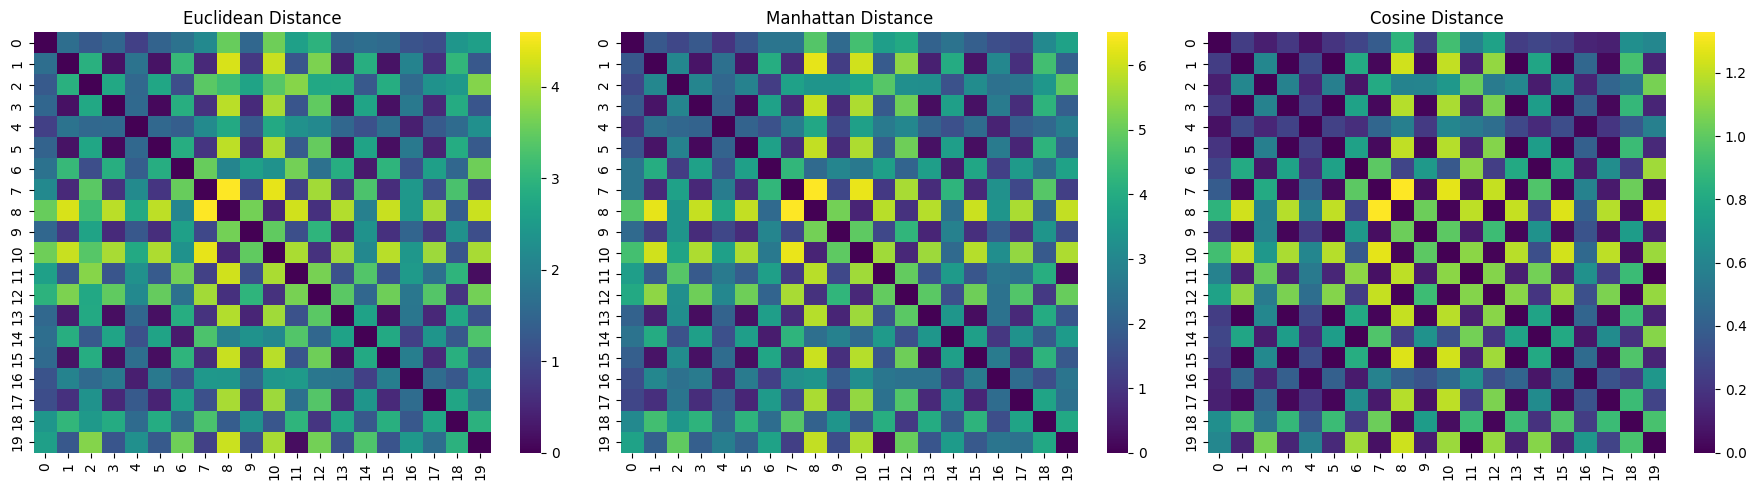

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(euclidean[:20, :20], ax=axes[0], cmap='viridis')
axes[0].set_title("Euclidean Distance")

sns.heatmap(manhattan[:20, :20], ax=axes[1], cmap='viridis')
axes[1].set_title("Manhattan Distance")

sns.heatmap(cosine[:20, :20], ax=axes[2], cmap='viridis')
axes[2].set_title("Cosine Distance")

plt.tight_layout()
plt.show()

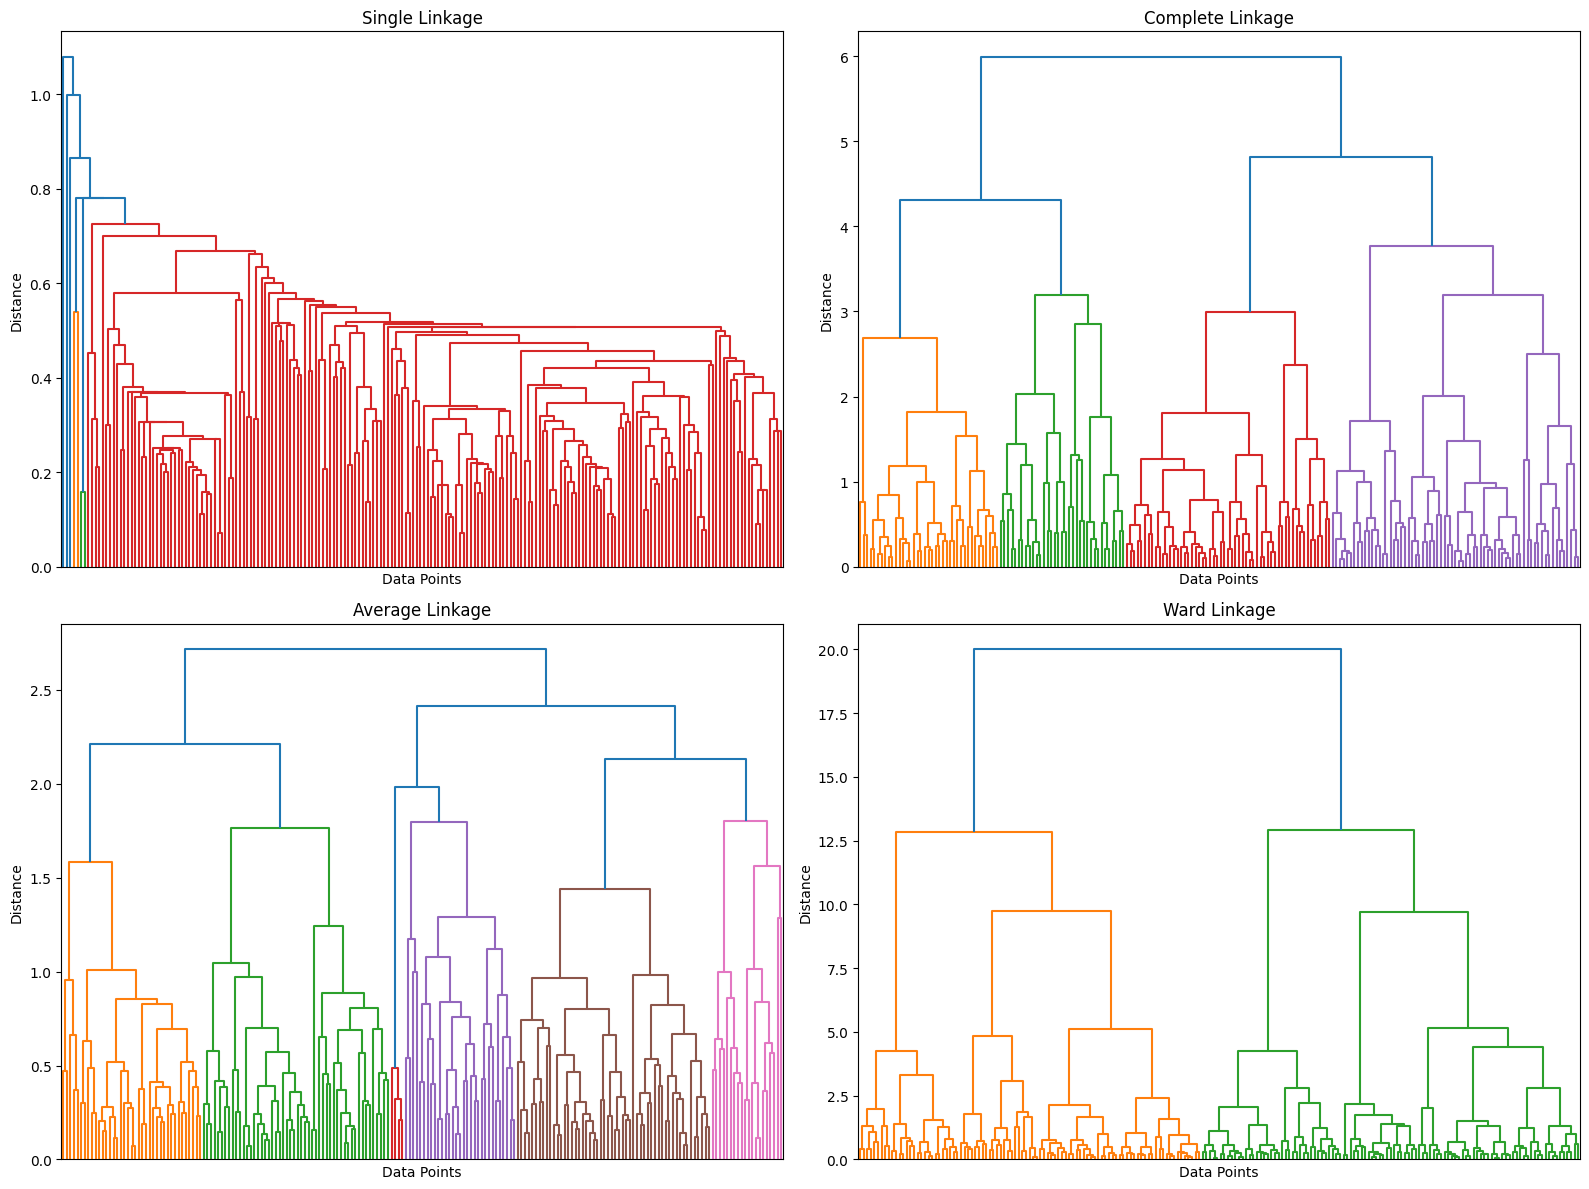

In [24]:
# Agglomerative Hierarchical Clustering

methods = ['single', 'complete', 'average', 'ward']

plt.figure(figsize=(16, 12))

for i, method in enumerate(methods, 1):

    plt.subplot(2, 2, i)

    if method == 'ward':
        Z = linkage(X_scaled, method=method, metric='euclidean')
    else:
        Z = linkage(X_scaled, method=method, metric='euclidean')

    dendrogram(Z, no_labels=True)

    plt.title(method.capitalize() + " Linkage")
    plt.xlabel("Data Points")
    plt.ylabel("Distance")

plt.tight_layout()
plt.show()

In [25]:
# Agglomerative Clustering with different linkage methods

results = {}

for method in methods:

    model = AgglomerativeClustering(
        n_clusters=5,
        linkage=method,
        metric='euclidean'
    )

    labels = model.fit_predict(X_scaled)

    results[method] = labels

    print("\n", method.upper(), "LINKAGE")
    print(pd.Series(labels).value_counts().sort_index())


 SINGLE LINKAGE
0    195
1      2
2      1
3      1
4      1
Name: count, dtype: int64

 COMPLETE LINKAGE
0    48
1    35
2    57
3    39
4    21
Name: count, dtype: int64

 AVERAGE LINKAGE
0    35
1    52
2    20
3    39
4    54
Name: count, dtype: int64

 WARD LINKAGE
0    66
1    45
2    39
3    28
4    22
Name: count, dtype: int64


In [26]:
from sklearn.cluster import BisectingKMeans

# Implement Divisive Clustering

divisive_model = BisectingKMeans(
    n_clusters=5,
    random_state=42
)

divisive_labels = divisive_model.fit_predict(X_scaled)

print("Divisive Hierarchical Clustering")
print("\nCluster Distribution:")

print(
    pd.Series(divisive_labels)
    .value_counts()
    .sort_index()
)

divisive_score = silhouette_score(
    X_scaled,
    divisive_labels
)

print("Divisive Clustering Silhouette Score:",
      divisive_score)

Divisive Hierarchical Clustering

Cluster Distribution:
0    36
1    47
2    20
3    36
4    61
Name: count, dtype: int64
Divisive Clustering Silhouette Score: 0.3573296716716955


In [27]:
# Experiment with Different Numbers of Clusters

cluster_range = [2, 3, 4, 5, 6]

for k in cluster_range:

    print("\nNumber of Clusters:", k)

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    print("Cluster Distribution:")
    print(pd.Series(labels).value_counts().sort_index())

    score = silhouette_score(X_scaled, labels)

    print("Silhouette Score:", round(score, 4))


Number of Clusters: 2
Cluster Distribution:
0    105
1     95
Name: count, dtype: int64
Silhouette Score: 0.318

Number of Clusters: 3
Cluster Distribution:
0    95
1    66
2    39
Name: count, dtype: int64
Silhouette Score: 0.3215

Number of Clusters: 4
Cluster Distribution:
0    67
1    66
2    39
3    28
Name: count, dtype: int64
Silhouette Score: 0.3615

Number of Clusters: 5
Cluster Distribution:
0    66
1    45
2    39
3    28
4    22
Name: count, dtype: int64
Silhouette Score: 0.39

Number of Clusters: 6
Cluster Distribution:
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64
Silhouette Score: 0.4201


In [28]:
# Comparison of Distance Measures and Linkage Methods

distance_metrics = ['euclidean', 'manhattan', 'cosine']
linkage_methods = ['single', 'complete', 'average', 'ward']

comparison_results = []

for metric in distance_metrics:

    for method in linkage_methods:

        # Ward supports only Euclidean distance
        if method == 'ward' and metric != 'euclidean':
            continue

        model = AgglomerativeClustering(
            n_clusters=5,
            metric=metric,
            linkage=method
        )

        labels = model.fit_predict(X_scaled)

        score = silhouette_score(
            X_scaled,
            labels,
            metric=metric
        )

        comparison_results.append({
            'Distance': metric,
            'Linkage': method,
            'Silhouette Score': round(score, 4)
        })

comparison_df = pd.DataFrame(comparison_results)

print("Clustering Comparison:")
display(
    comparison_df.sort_values(
        by='Silhouette Score',
        ascending=False
    )
)

Clustering Comparison:


,Distance,Linkage,Silhouette Score
8,cosine,complete,0.6641
9,cosine,average,0.6522
2,euclidean,average,0.4096
6,manhattan,average,0.4056
1,euclidean,complete,0.4000
5,manhattan,complete,0.3904
3,euclidean,ward,0.3900
0,euclidean,single,0.0030
7,cosine,single,-0.0177
4,manhattan,single,-0.0543


In [29]:
from sklearn.cluster import AgglomerativeClustering, BisectingKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Agglomerative Clustering
agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

agg_labels = agg_model.fit_predict(X_scaled)

# Divisive Clustering
div_model = BisectingKMeans(
    n_clusters=5,
    random_state=42
)

div_labels = div_model.fit_predict(X_scaled)

# Calculate Silhouette Scores
agg_score = silhouette_score(X_scaled, agg_labels)
div_score = silhouette_score(X_scaled, div_labels)

print("AGGLOMERATIVE CLUSTERING")
print("Silhouette Score:", round(agg_score, 4))

print("\nDIVISIVE CLUSTERING")
print("Silhouette Score:", round(div_score, 4))

print("\nComparison:")
print("Agglomerative:", round(agg_score, 4))
print("Divisive:", round(div_score, 4))

# Compare agreement between cluster assignments
ari = adjusted_rand_score(agg_labels, div_labels)

print("\nAdjusted Rand Index:", round(ari, 4))

AGGLOMERATIVE CLUSTERING
Silhouette Score: 0.39

DIVISIVE CLUSTERING
Silhouette Score: 0.3573

Comparison:
Agglomerative: 0.39
Divisive: 0.3573

Adjusted Rand Index: 0.5375


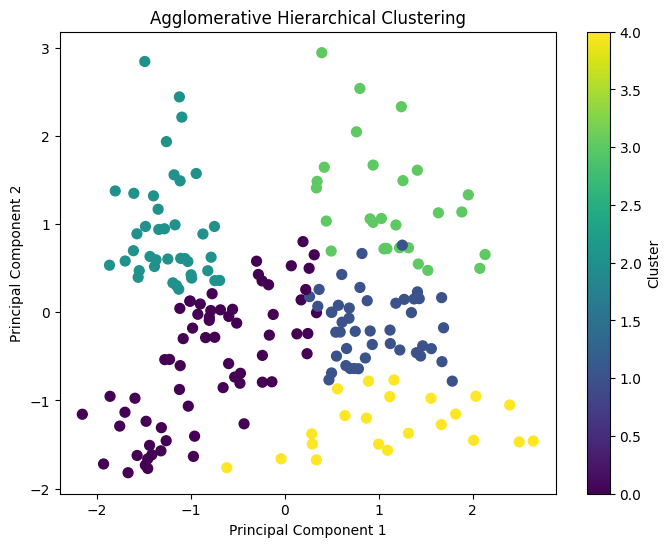

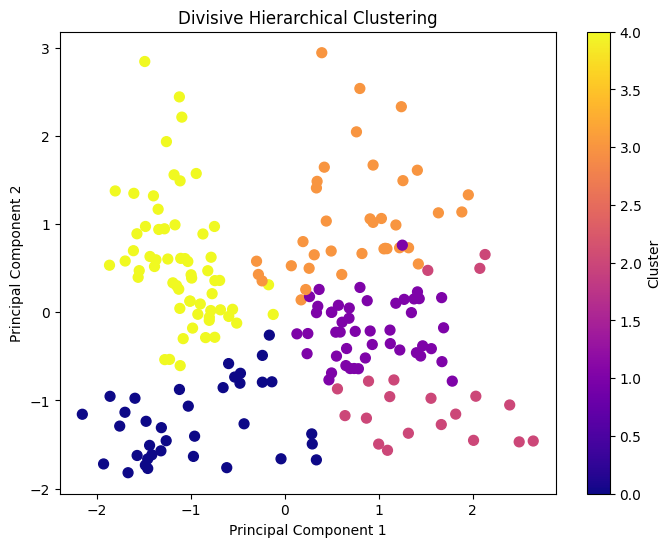

In [16]:
# PCA Visualization

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Visualize Agglomerative Clustering
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agg_labels,
    cmap='viridis',
    s=50
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()


# Visualize Divisive Clustering
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=div_labels,
    cmap='plasma',
    s=50
)

plt.title("Divisive Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [30]:
# Add cluster labels to original data

cluster_data = data.copy()

cluster_data['Cluster'] = agg_labels

# Calculate average customer characteristics
cluster_summary = cluster_data.groupby(
    'Cluster'
)[['Age', 'Annual Income (k$)',
   'Spending Score (1-100)']].mean()

print("Customer Cluster Profiles:")
display(cluster_summary.round(2))

Customer Cluster Profiles:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,26.56,47.36,56.79
1,56.40,55.29,48.36
2,32.69,86.54,82.13
3,43.89,91.29,16.68
4,44.32,25.77,20.27


Hierarchical Clustering was successfully implemented using Agglomerative and Divisive approaches. Different distance measures and linkage methods produced different cluster formations. Cosine distance with Complete Linkage achieved the highest Silhouette Score of 0.6641. The experiment demonstrated how hierarchical clustering can be used to identify meaningful customer groups based on their characteristics.